In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [23]:
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from scipy.stats import skew, kurtosis
from package import training_and_evaluation
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re

In [3]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [4]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [5]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [6]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera',
  'ip_address': nan,
 

# Feature Set 1 - Packet Count and Total Size
- For this experiment, I will be testing only feature `packet count`, and `total size`
- We'll experiment different window size

In [7]:
def calculate_features(file_paths: Iterable[str], window: int) -> Tuple[pd.DataFrame, float]:
    columns = ["frame.time_epoch", "frame.len", "eth.src"]
    all_features = []

    startTime = time.perf_counter()
    for file_path in file_paths:
        df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category"
            },
        )
        start = df["frame.time_epoch"].min()

        df["window"] = (
            (df["frame.time_epoch"] - start) // window
        ).astype("int32")

        grouped = df.groupby(
            ["window", "eth.src"],
            sort=False,
            observed=True,
        )["frame.len"]

        basic_features = grouped.agg(
            packet_count="size",
            total_bytes="sum",
        ).reset_index()
        all_features.append(basic_features)
    endTime = time.perf_counter()

    return pd.concat(all_features, ignore_index=True), endTime - startTime


In [8]:
def label_features(features: pd.DataFrame, device_mapping: Dict[str, Dict[str, str]]) -> pd.DataFrame:
    # Check if eth.src is in device_mapping, and get label is_iot_device, device_type, and vendor
    features["is_iot_device"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("is_iot_device", 0)
    )
    features["device_type"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("device_type", "unknown")
    )
    features["vendor"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("vendor", "unknown")
    )
    return features
    

In [9]:
minWindow, maxWindow = 1, 300

In [10]:
metrics = {}
feature_calculate_metric = {}
training_features = ["packet_count", "total_bytes"]
label = "is_iot_device"
for window in range(minWindow, maxWindow + 1):
    print(f"------------WINDOW: {window}-------------")
    features, time_taken = calculate_features(csv_files_1, window)
    feature_calculate_metric[window] = time_taken
    labeled_dataset = label_features(features, device_dict_1)
    X, y = labeled_dataset[training_features], labeled_dataset[label]
    experiment_results = training_and_evaluation(X, y)
    metrics[window] = experiment_results
    print(f"------------------------------------------")


------------WINDOW: 1-------------
Training and evaluating with:
Features: ['packet_count', 'total_bytes']
Label: [0 1]
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=SMOTE, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=SMOTE, scaler=StandardScaler
------------------------------------------
------------WINDOW: 2-------------
Training and evaluating with:
Features: ['packet_count', 'total_bytes']
Label: [0 1]
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=SMOTE, s

In [19]:
from copy import deepcopy
from datetime import datetime


metric_copy = deepcopy(metrics)
combined_df = pd.concat(
    [
        df.assign(window=window)
        for window, df in metric_copy.items()
    ],
    ignore_index=True,
)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"combined_results_{timestamp}.csv"

combined_df.to_csv(filename, index=False)

## Performance Plotting

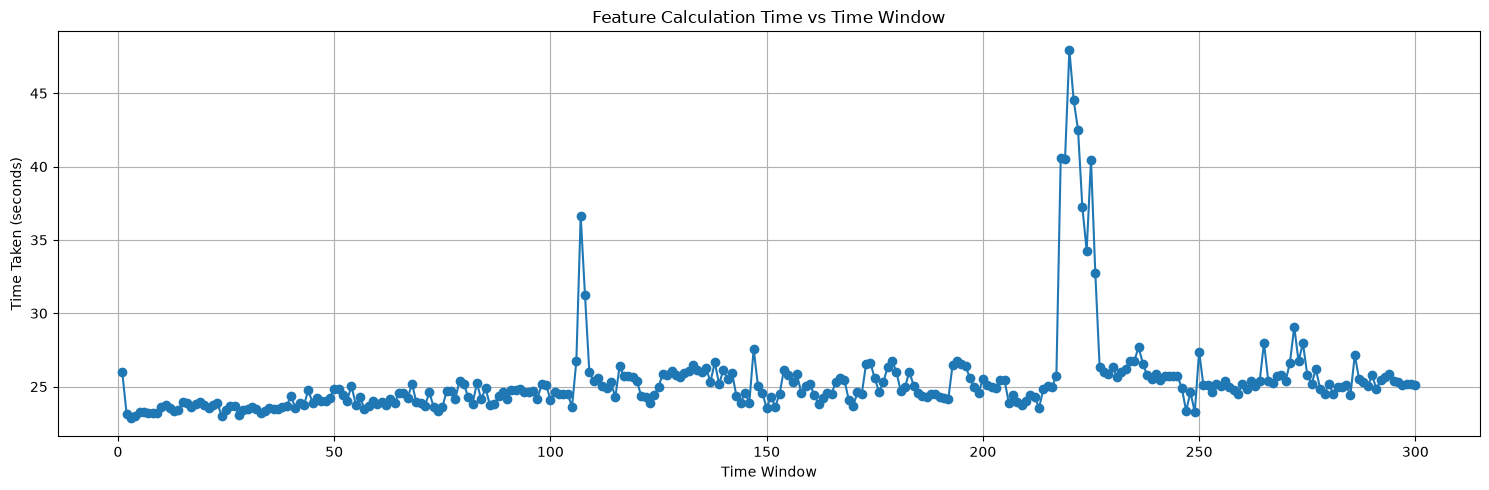

In [ ]:
x = sorted(feature_calculate_metric.keys())
y = [feature_calculate_metric[k] for k in x]

plt.figure(figsize=(15, 5))
plt.plot(x, y, marker="o")
plt.title("Feature Calculation Time vs Time Window")
plt.xlabel("Time Window")
plt.ylabel("Time Taken (seconds)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [28]:




def plot_results(
    combined_results: pd.DataFrame,
    output_dir: str = "result_plots",
) -> None:
    """
    For every (model, sample_method) pair, generate:
      1. Average accuracy by window, with min/max error bars
      2. Average train time by window, with min/max error bars
    """
    required_columns = {
        "model",
        "sample_method",
        "window",
        "accuracy",
        "train_time",
    }

    missing = required_columns - set(combined_results.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    output_path = Path(f"{output_dir}-{timestamp}")
    output_path.mkdir(parents=True, exist_ok=True)

    # Ensure numeric columns are interpreted correctly.
    df = combined_results.copy()
    df["window"] = pd.to_numeric(df["window"], errors="coerce")
    df["accuracy"] = pd.to_numeric(df["accuracy"], errors="coerce")
    df["train_time"] = pd.to_numeric(df["train_time"], errors="coerce")

    df = df.dropna(
        subset=["model", "sample_method", "window", "accuracy", "train_time"]
    )

    grouped = (
        df.groupby(
            ["model", "sample_method", "window"],
            observed=True,
            sort=True,
        )
        .agg(
            accuracy_mean=("accuracy", "mean"),
            accuracy_min=("accuracy", "min"),
            accuracy_max=("accuracy", "max"),
            train_time_mean=("train_time", "mean"),
            train_time_min=("train_time", "min"),
            train_time_max=("train_time", "max"),
        )
        .reset_index()
    )

    for (model, sample_method), pair_df in grouped.groupby(
        ["model", "sample_method"],
        observed=True,
        sort=False,
    ):
        pair_df = pair_df.sort_values("window")

        safe_name = re.sub(
            r"[^A-Za-z0-9_-]+",
            "_",
            f"{model}_{sample_method}",
        )

        # -------------------------
        # Accuracy plot
        # -------------------------
        mean = pair_df["accuracy_mean"]

        plt.figure(figsize=(16, 5))

        plt.errorbar(
            pair_df["window"],
            mean,
            yerr=[
                mean - pair_df["accuracy_min"],
                pair_df["accuracy_max"] - mean,
            ],
            marker="o",
            markersize=4,
            linewidth=1.5,
            capsize=4,
            label="Mean with min/max",
        )

        plt.title(f"Accuracy vs Window\n{model} — {sample_method}")
        plt.xlabel("Window")
        plt.ylabel("Accuracy")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            output_path / f"{safe_name}_accuracy.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()

        # -------------------------
        # Training-time plot
        # -------------------------
        mean = pair_df["train_time_mean"]

        plt.figure(figsize=(16, 5))

        plt.errorbar(
            pair_df["window"],
            mean,
            yerr=[
                mean - pair_df["train_time_min"],
                pair_df["train_time_max"] - mean,
            ],
            marker="o",
            markersize=4,
            linewidth=1.5,
            capsize=4,
            label="Mean with min/max",
        )

        plt.title(f"Training Time vs Window\n{model} — {sample_method}")
        plt.xlabel("Window")
        plt.ylabel("Training Time (seconds)")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            output_path / f"{safe_name}_train_time.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()

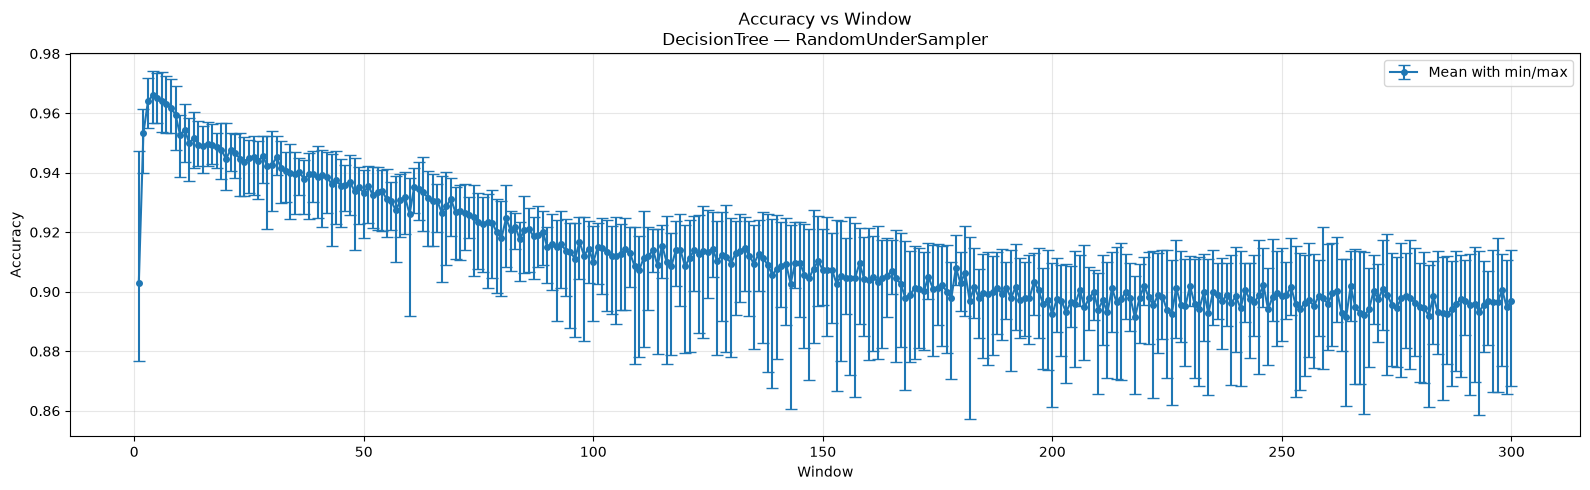

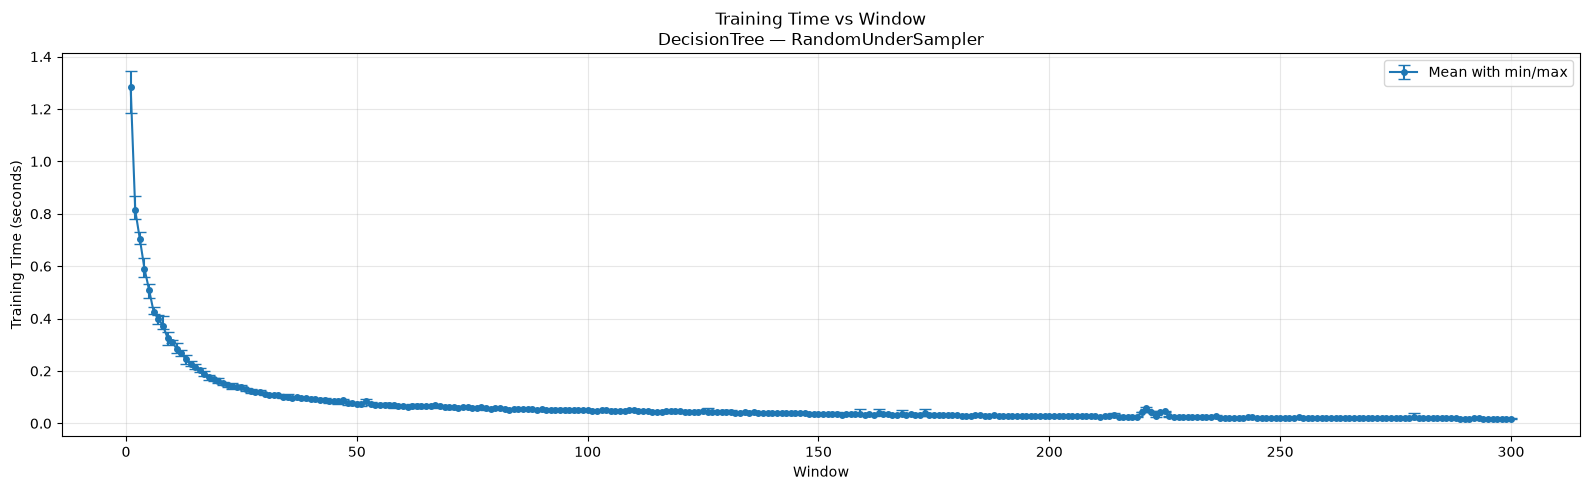

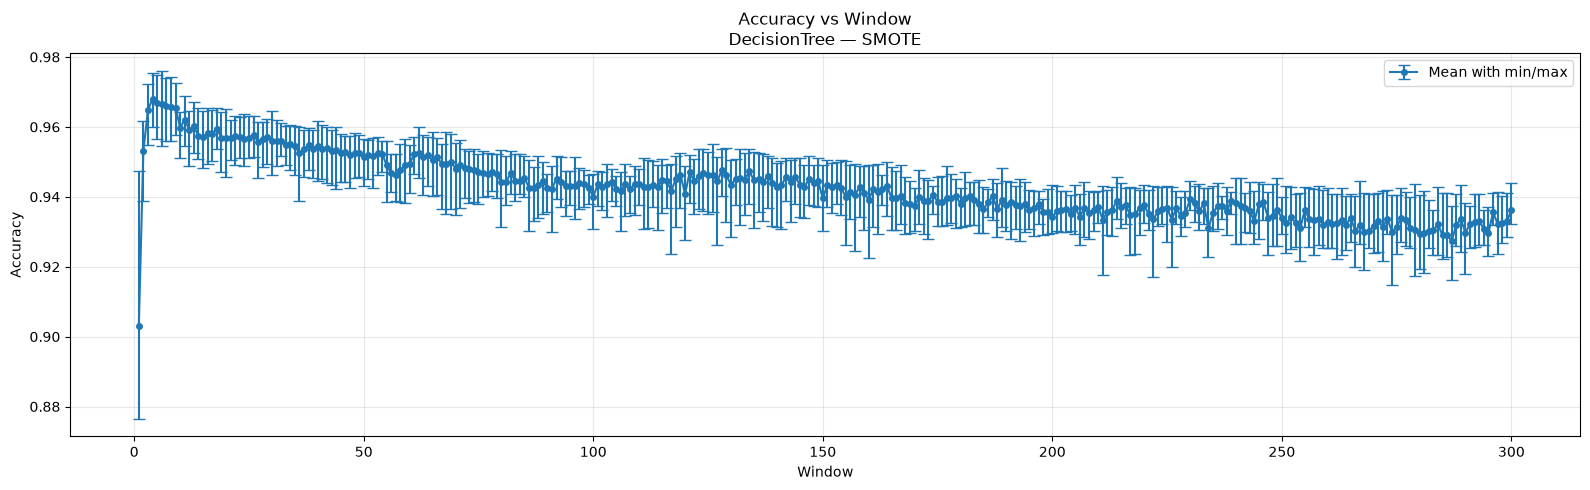

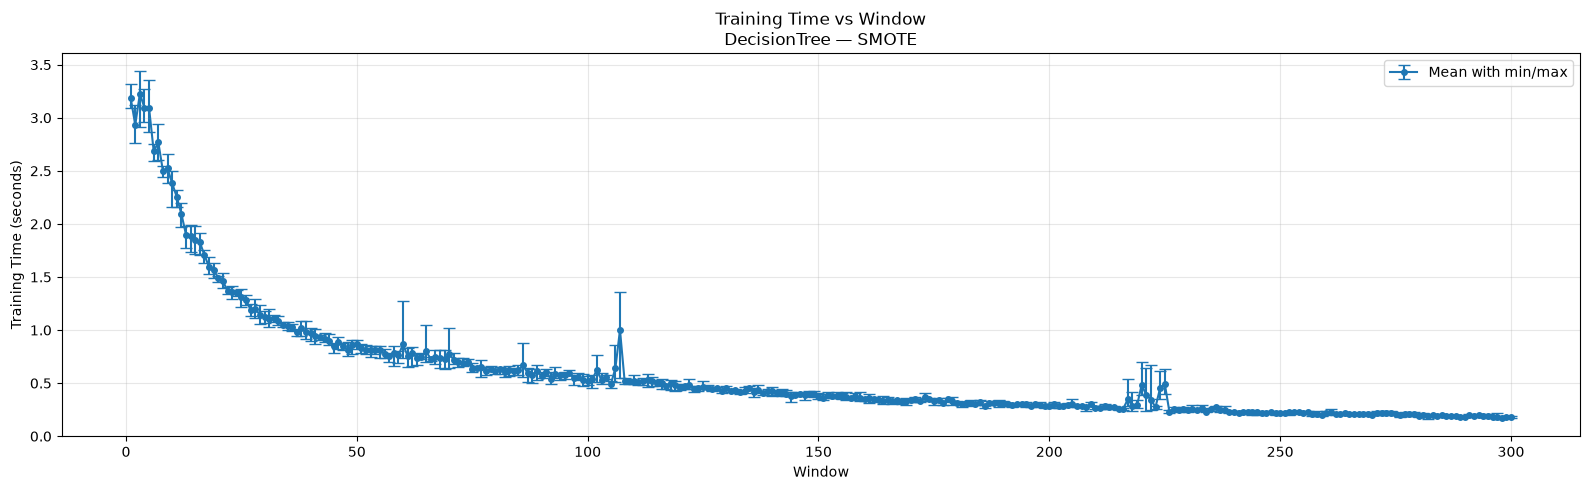

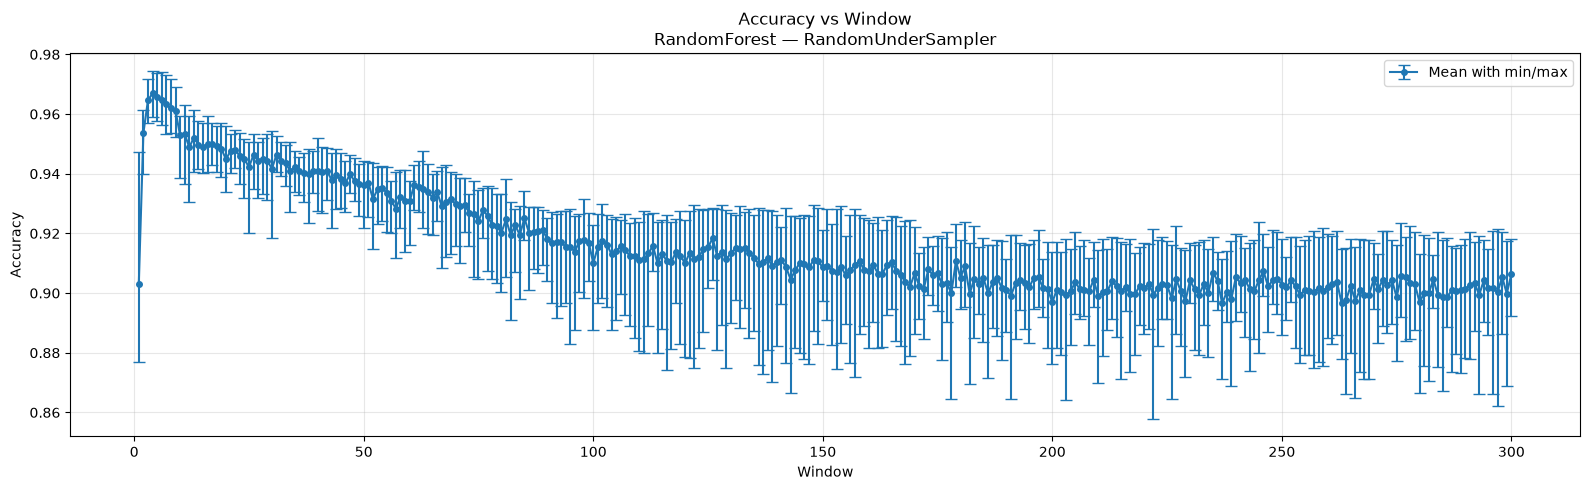

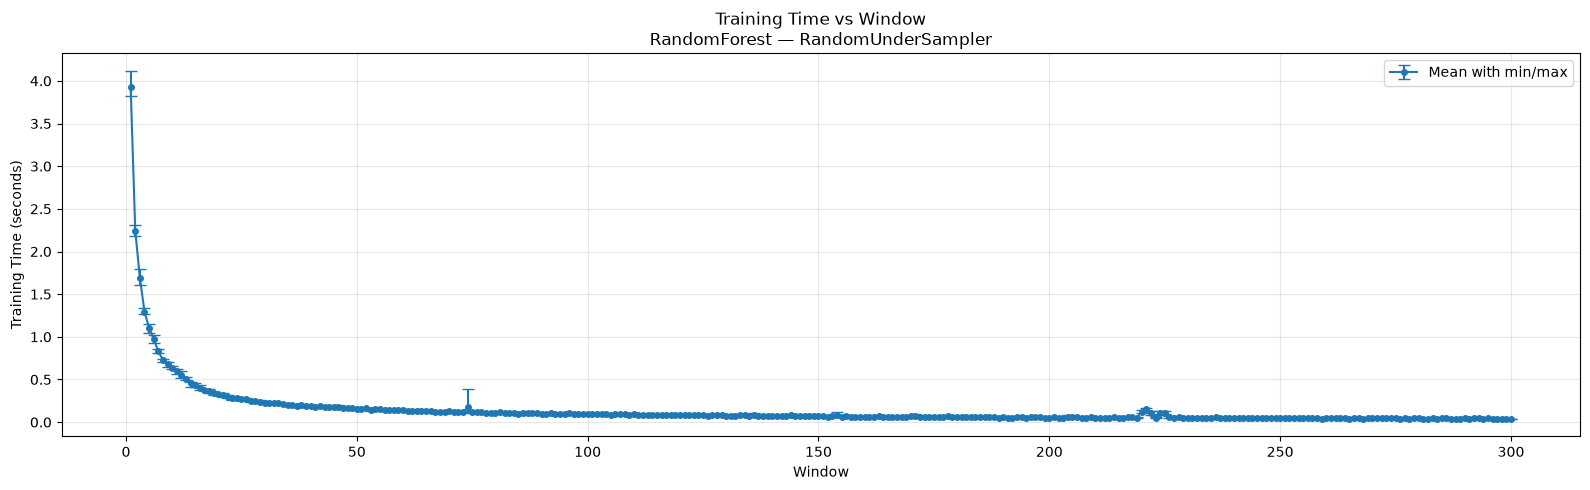

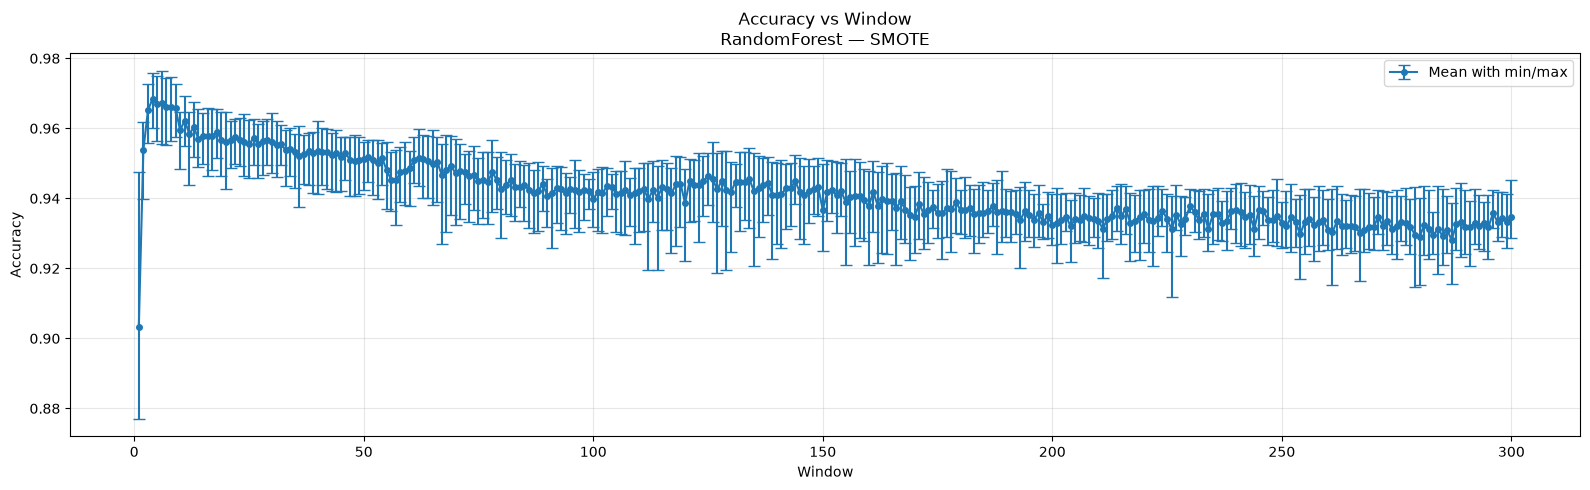

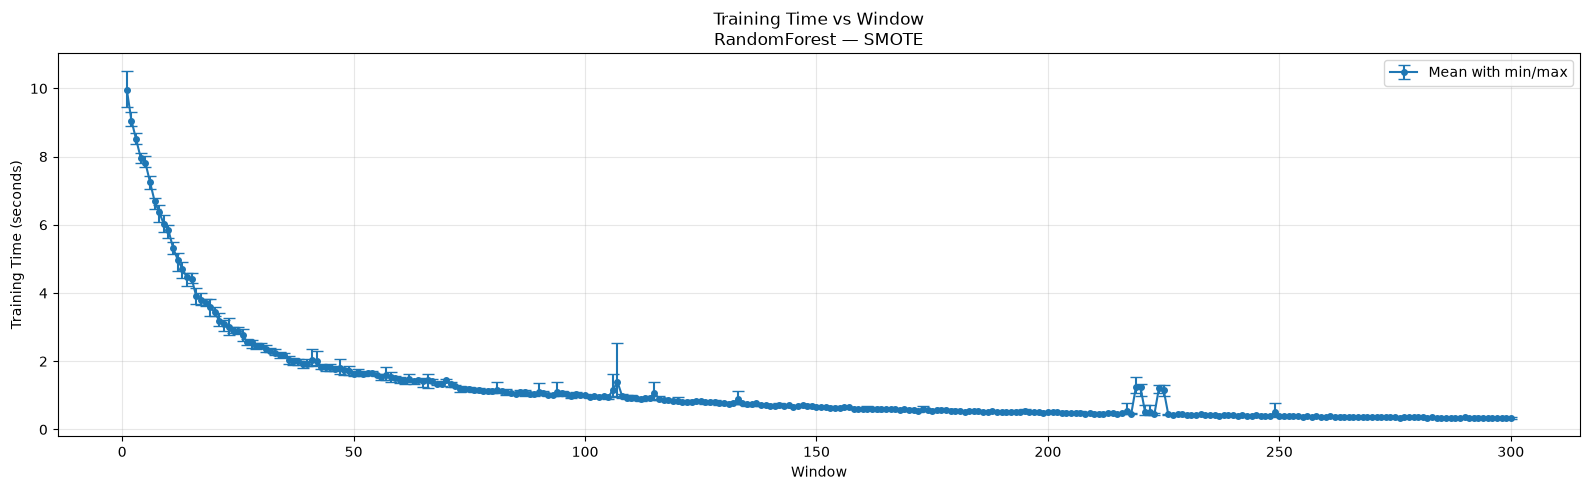

In [29]:
plot_results(combined_df, output_dir="performance-plot")